# Q5–Q6. Severe Injuries by Reported Cause and Intersection Control

**Course** — CSC17104 · Programming for Data Science  
**Group** — Group 14 · Tam Khuyển  
**Question owner** — Nguyễn Gia Kiệt (24127195)  
**Scope** — Non-ML · 2018–2024 comparison period  
**Dataset** — Traffic Accidents, Chicago (Kaggle snapshot)  
**Prerequisite** — Run [notebook 01](01_collection_exploration.ipynb) to generate `data/processed/traffic_accidents_clean.csv`.  
**Assistance log** — [LLM_USAGE.md](../LLM_USAGE.md)

## Introduction

**Research questions**

- **Q5** — Which reported causes have the highest severe-injury shares, and how do the rankings change within collision types or after excluding undetermined causes?
- **Q6** — How do severe-injury shares differ by intersection control, collision type, and daylight versus darkness?

**Motivation**

Road-safety analysts can use these comparisons to identify reported cause, collision, and intersection groups that warrant further study.

**Analysis plan**

A severe-injury crash has at least one reported fatal or incapacitating injury. Q5 compares eligible cause groups and checks how rankings change. Q6 compares records on common collision and lighting strata and summarizes counts and injury shares by hour and weekday.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analysis_utils import event_summary, load_processed, restrict

sns.set_theme(style="whitegrid")
crashes = load_processed(ROOT)
period = restrict(crashes, crashes["crash_year"].between(2018, 2024), "Use 2018-2024 comparison years")

computed_severe = period["injuries_fatal"].gt(0) | period["injuries_incapacitating"].gt(0)
assert computed_severe.eq(period["has_severe_injury"]).all()
print(f"Overall severe-injury share in the comparison years: {period['has_severe_injury'].mean():.2%}")

data/processed/traffic_accidents_clean.csv: 209,275 rows, 29 columns
Use 2018-2024 comparison years: 209,275 -> 181,051 rows (28,224 excluded)
Overall severe-injury share in the comparison years: 3.39%


## Q5. Which recorded causes have high severe-injury shares?

**Question.** Which sufficiently frequent primary cause labels have the highest share of severe-injury crashes? Does the ranking move within first-collision types, and what changes when `UNABLE TO DETERMINE` is excluded?

**Motivation.** Traffic-safety analysts can identify cause and collision categories to investigate further. The cause is assigned during crash reporting and may reflect what was established in the investigation.

**Approach.** D3 defines a severe outcome, D4 compares within collision type, D5 reports 95% Wilson intervals, and D6 checks the effect of retaining or excluding undetermined cause labels and changing the total-sample cutoff. Pool only causes with at least 500 records for ranking. For within-type rankings, require at least 100 records in each cause/type cell. These cutoffs reduce instability from small denominators. Wilson intervals treat records as independent and are descriptive. There is no adjustment for the number of cause comparisons.

In [2]:
CAUSE = "prim_contributory_cause"
COLLISION = "first_crash_type"
SEVERE = "has_severe_injury"
undetermined = "UNABLE TO DETERMINE"
minimum_cause_count = 500
minimum_cell_count = 100


def rank_causes(frame, minimum):
    rates = event_summary(frame, [CAUSE], SEVERE)
    eligible = rates.loc[rates["crashes"].ge(minimum)].copy()
    print(f"Ranking eligibility: {len(rates)} cause labels -> {len(eligible)} with at least {minimum} records")
    return (
        eligible.sort_values(["pct", CAUSE], ascending=[False, True])
        .assign(rank=lambda rates: np.arange(1, len(rates) + 1))
        .reset_index(drop=True)
    )


all_cause_rates = rank_causes(period, minimum_cause_count)
known = restrict(
    period, period[CAUSE].ne(undetermined),
    "Q5 sensitivity: exclude UNABLE TO DETERMINE",
)
known_rates = rank_causes(known, minimum_cause_count)
overall_baselines = pd.DataFrame({
    "cohort": ["All labels", "Exclude UNABLE TO DETERMINE"],
    "crashes": [len(period), len(known)],
    "severe_crashes": [period[SEVERE].sum(), known[SEVERE].sum()],
    "severe_pct": [100 * period[SEVERE].mean(), 100 * known[SEVERE].mean()],
})
display(overall_baselines.round(2))

ranking_comparison = all_cause_rates.merge(
    known_rates[[CAUSE, "rank", "pct"]], on=CAUSE, how="left",
    suffixes=("_all", "_exclude_undetermined"), validate="one_to_one",
)
print(f"Q5 ranking join: {len(all_cause_rates)} -> {len(ranking_comparison)} cause rows")
observed_both = ranking_comparison["rank_exclude_undetermined"].notna()
assert np.allclose(
    ranking_comparison.loc[observed_both, "pct_all"],
    ranking_comparison.loc[observed_both, "pct_exclude_undetermined"],
)
display(ranking_comparison.round(2))
higher_cutoff = rank_causes(period, 1000)
display(higher_cutoff[[CAUSE, "crashes", "pct", "rank"]].head(5).round(2))

assigned = restrict(known, known[CAUSE].ne("NOT APPLICABLE"), "Q5 exclude NOT APPLICABLE for named-cause comparisons")
assigned_rates = rank_causes(assigned, minimum_cause_count)

Ranking eligibility: 40 cause labels -> 22 with at least 500 records
Q5 sensitivity: exclude UNABLE TO DETERMINE: 181,051 -> 129,960 rows (51,091 excluded)
Ranking eligibility: 39 cause labels -> 21 with at least 500 records


,cohort,crashes,severe_crashes,severe_pct
0,All labels,181051,6146,3.39
1,Exclude UNABLE TO DETERMINE,129960,4693,3.61


Q5 ranking join: 22 -> 22 cause rows


,prim_contributory_cause,crashes,events,pct_all,low_pct,high_pct,rank_all,rank_exclude_undetermined,pct_exclude_undetermined
0,PHYSICAL CONDITION OF DRIVER,675,80,11.85,9.63,14.51,1,1.0,11.85
1,UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN...,753,76,10.09,8.14,12.45,2,2.0,10.09
2,"OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELE...",1669,122,7.31,6.16,8.66,3,3.0,7.31
3,DISREGARDING OTHER TRAFFIC SIGNS,969,65,6.71,5.30,8.46,4,4.0,6.71
4,DISREGARDING TRAFFIC SIGNALS,13205,864,6.54,6.13,6.98,5,5.0,6.54
5,"VISION OBSCURED (SIGNS, TREE LIMBS, BUILDINGS,...",1577,103,6.53,5.41,7.86,6,6.0,6.53
6,DRIVING ON WRONG SIDE/WRONG WAY,1066,69,6.47,5.15,8.11,7,7.0,6.47
7,FAILING TO YIELD RIGHT-OF-WAY,37544,1687,4.49,4.29,4.71,8,8.0,4.49
8,FAILING TO REDUCE SPEED TO AVOID CRASH,9406,406,4.32,3.92,4.75,9,9.0,4.32
9,DISTRACTION - FROM OUTSIDE VEHICLE,659,26,3.95,2.71,5.72,10,10.0,3.95


Ranking eligibility: 40 cause labels -> 17 with at least 1000 records


,prim_contributory_cause,crashes,pct,rank
0,"OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELE...",1669,7.31,1
1,DISREGARDING TRAFFIC SIGNALS,13205,6.54,2
2,"VISION OBSCURED (SIGNS, TREE LIMBS, BUILDINGS,...",1577,6.53,3
3,DRIVING ON WRONG SIDE/WRONG WAY,1066,6.47,4
4,FAILING TO YIELD RIGHT-OF-WAY,37544,4.49,5


Q5 exclude NOT APPLICABLE for named-cause comparisons: 129,960 -> 125,690 rows (4,270 excluded)


Ranking eligibility: 38 cause labels -> 20 with at least 500 records


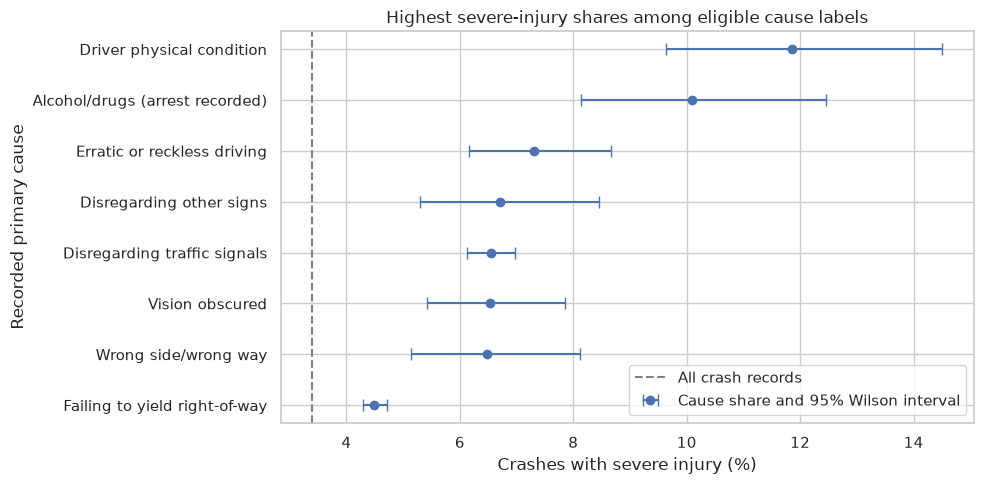

In [3]:
readable_cause = {
    "PHYSICAL CONDITION OF DRIVER": "Driver physical condition",
    "UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN ARREST IS EFFECTED)": "Alcohol/drugs (arrest recorded)",
    "OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELESS, NEGLIGENT OR AGGRESSIVE MANNER": "Erratic or reckless driving",
    "DISREGARDING OTHER TRAFFIC SIGNS": "Disregarding other signs",
    "DISREGARDING TRAFFIC SIGNALS": "Disregarding traffic signals",
    "VISION OBSCURED (SIGNS, TREE LIMBS, BUILDINGS, ETC.)": "Vision obscured",
    "DRIVING ON WRONG SIDE/WRONG WAY": "Wrong side/wrong way",
    "FAILING TO YIELD RIGHT-OF-WAY": "Failing to yield right-of-way",
}
q5_top = assigned_rates.head(8).sort_values("pct")
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(
    q5_top["pct"], q5_top[CAUSE].replace(readable_cause),
    xerr=np.vstack([q5_top["pct"] - q5_top["low_pct"], q5_top["high_pct"] - q5_top["pct"]]),
    fmt="o", capsize=4, label="Cause share and 95% Wilson interval",
)
ax.axvline(100 * period[SEVERE].mean(), color="gray", linestyle="--", label="All crash records")
ax.set(title="Highest severe-injury shares among eligible cause labels", xlabel="Crashes with severe injury (%)", ylabel="Recorded primary cause")
ax.legend()
fig.tight_layout()
plt.show()

### Compare causes within common collision types

We select the five most frequent collision types in the period. Within each, we exclude `UNABLE TO DETERMINE` and `NOT APPLICABLE`, then rank all sufficiently frequent cause labels, and the heatmap shows how the eight highest-ranked pooled causes behave. Blank cells fell below the 100-record cutoff. A pooled high rate can reflect the mix of collisions associated with the label. Within-type comparisons condition on one recorded factor and remain descriptive.

Q5 restrict to the five most common first-collision types: 125,690 -> 114,140 rows (11,550 excluded)
Q5 minimum 100 reports per cause/collision cell: 180 -> 70 rows (110 excluded)
Top eligible cause by collision type:


,first_crash_type,prim_contributory_cause,crashes,events,pct,low_pct,high_pct,rank_within_type
34,ANGLE,UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN...,140,24,17.14,11.80,24.24,1
53,PEDESTRIAN,FAILING TO REDUCE SPEED TO AVOID CRASH,316,84,26.58,22.01,31.71,1
98,REAR END,PHYSICAL CONDITION OF DRIVER,228,25,10.96,7.54,15.69,1
132,SIDESWIPE SAME DIRECTION,"OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELE...",225,8,3.56,1.81,6.86,1
177,TURNING,UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN...,130,12,9.23,5.36,15.44,1


Q5 show pooled leaders in the within-type table: 70 -> 25 rows (45 excluded)


,first_crash_type,prim_contributory_cause,crashes,events,pct,rank_within_type
34,ANGLE,UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN...,140,24,17.14,1
26,ANGLE,"OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELE...",294,26,8.84,2
2,ANGLE,DISREGARDING OTHER TRAFFIC SIGNS,545,36,6.61,3
5,ANGLE,DISREGARDING TRAFFIC SIGNALS,9196,578,6.29,4
10,ANGLE,DRIVING ON WRONG SIDE/WRONG WAY,322,20,6.21,5
17,ANGLE,FAILING TO YIELD RIGHT-OF-WAY,13998,434,3.10,10
35,ANGLE,"VISION OBSCURED (SIGNS, TREE LIMBS, BUILDINGS,...",582,13,2.23,14
62,PEDESTRIAN,"OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELE...",105,27,25.71,2
42,PEDESTRIAN,DISREGARDING TRAFFIC SIGNALS,270,69,25.56,3
69,PEDESTRIAN,"VISION OBSCURED (SIGNS, TREE LIMBS, BUILDINGS,...",284,62,21.83,4


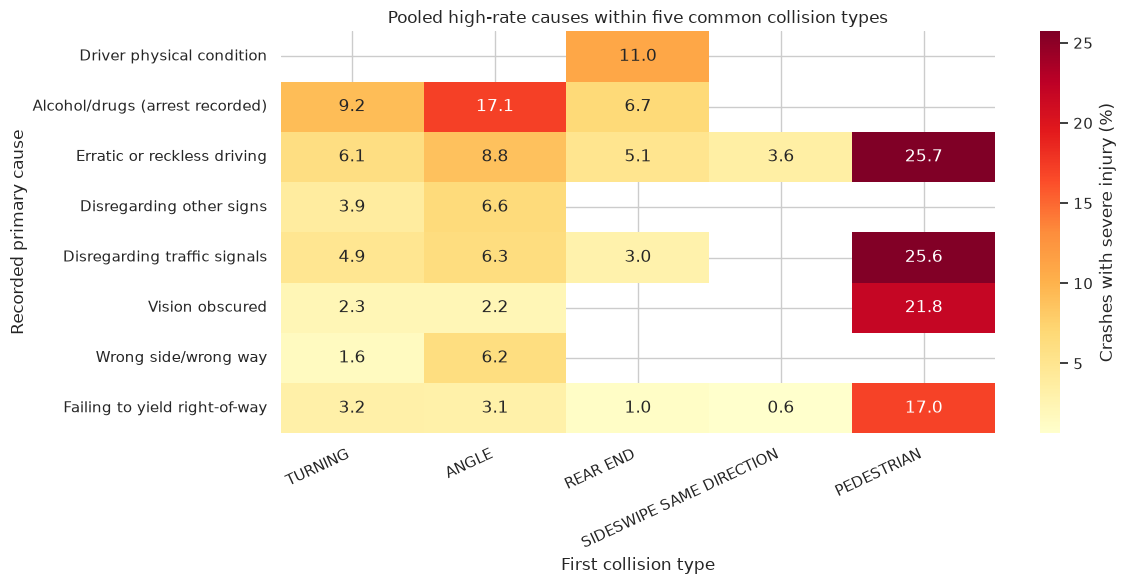

In [4]:
common_types = period[COLLISION].value_counts().head(5).index
within_records = restrict(
    assigned, assigned[COLLISION].isin(common_types), "Q5 restrict to the five most common first-collision types"
)
within = event_summary(within_records, [COLLISION, CAUSE], SEVERE)
eligible_within = restrict(within, within["crashes"].ge(minimum_cell_count), "Q5 minimum 100 reports per cause/collision cell")
eligible_within = eligible_within.sort_values([COLLISION, "pct", CAUSE], ascending=[True, False, True])
eligible_within["rank_within_type"] = eligible_within.groupby(COLLISION, observed=True).cumcount() + 1
print("Top eligible cause by collision type:")
display(eligible_within.groupby(COLLISION, observed=True).head(1).round(2))

pooled_leaders = assigned_rates.head(8)[CAUSE]
selected_within = restrict(eligible_within, eligible_within[CAUSE].isin(pooled_leaders), "Q5 show pooled leaders in the within-type table")
display(
    selected_within[[COLLISION, CAUSE, "crashes", "events", "pct", "rank_within_type"]].round(2)
)
heat = (
    selected_within.pivot(index=CAUSE, columns=COLLISION, values="pct")
    .reindex(index=pooled_leaders, columns=common_types)
    .rename(index=readable_cause)
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Crashes with severe injury (%)"}, ax=ax)
ax.set(title="Pooled high-rate causes within five common collision types", xlabel="First collision type", ylabel="Recorded primary cause")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fig.tight_layout()
plt.show()

### Q5 results and interpretation

Among causes with at least 500 records, **driver physical condition** ranked first at **11.85%** (80/675, 95% Wilson **9.63–14.51%**) and the **alcohol/drug label recorded when an arrest occurs** ranked second at **10.09%** (76/753, **8.14–12.45%**). The overall comparison-period share was **3.39%**. The leader intervals overlap, so treat the order as a descriptive ranking. Raising the eligibility cutoff to 1,000 removes both groups from the ranking and puts **erratic or reckless driving** first (**7.31%**).

The highest-ranked cause depended on the collision type and cell support. For example, driver physical condition led rear-end crashes (**10.96%**, 25/228). The alcohol/drug label led angle crashes (**17.14%**, 24/140). In pedestrian crashes, the highest eligible share was for failing to reduce speed to avoid a crash (**26.58%**, 84/316). Those examples use a minimum of 100 records in each cause/type cell.

The undetermined category contained **51,091** records and ranked 14th (**2.84% severe**). Excluding it raises the overall share from **3.39% to 3.61%**. Rates and relative order of the remaining labels are unchanged because their own numerators and denominators are unchanged. The reported cause can depend on evidence, investigation and arrest practices. These results identify groups worth further examination and cannot establish the effect of the causal factors named in the reports.

## Q6. How does severe-injury share differ by intersection control?

**Question.** Among intersection-related crash records, do severe-injury shares differ for traffic signals, stop signs/flashers and no controls after comparing day versus night and accounting for first collision type? How are the selected crash records distributed by hour and day of week?

**Motivation.** A road-safety analyst can identify times and collision types that deserve further study. A fair comparison of device safety would also require traffic and intersection data.

**Approach.** Use the intersection indicator and three exact reported control labels. Day is `DAYLIGHT`; night includes `DARKNESS` and `DARKNESS, LIGHTED ROAD`. We exclude dawn, dusk and unknown lighting from the main comparison. Rates and date/time pivots are conditional on a crash having been recorded. D2 covers the hourly/weekday reshaping, D3 defines severity and lighting phase, and D4 compares within collision/phase strata. Wilson intervals in the plot provide descriptive uncertainty.

In [5]:
DEVICE = "traffic_control_device"
devices = ["TRAFFIC SIGNAL", "STOP SIGN/FLASHER", "NO CONTROLS"]
lighting_phase = {"DAYLIGHT": "Day", "DARKNESS": "Night", "DARKNESS, LIGHTED ROAD": "Night"}
labels = {"TRAFFIC SIGNAL": "Signal", "STOP SIGN/FLASHER": "Stop sign/flasher", "NO CONTROLS": "No controls"}

intersection = restrict(period, period["intersection_related_i"].eq("Y"), "Q6 intersection-related records")
controls = restrict(intersection, intersection[DEVICE].isin(devices), "Q6 select the three control categories")
cohort = restrict(controls, controls["lighting_condition"].isin(lighting_phase), "Q6 keep clear day/night categories")
cohort["phase"] = cohort["lighting_condition"].map(lighting_phase)
display(event_summary(cohort, [DEVICE], SEVERE).round(2))
phase_rates = event_summary(cohort, ["phase", DEVICE], SEVERE)
display(phase_rates.round(2))

Q6 intersection-related records: 181,051 -> 172,331 rows (8,720 excluded)
Q6 select the three control categories: 172,331 -> 167,136 rows (5,195 excluded)
Q6 keep clear day/night categories: 167,136 -> 156,698 rows (10,438 excluded)


,traffic_control_device,crashes,events,pct,low_pct,high_pct
0,NO CONTROLS,20522,714,3.48,3.24,3.74
1,STOP SIGN/FLASHER,39269,1213,3.09,2.92,3.26
2,TRAFFIC SIGNAL,96907,3450,3.56,3.45,3.68


,phase,traffic_control_device,crashes,events,pct,low_pct,high_pct
0,Day,NO CONTROLS,14940,464,3.11,2.84,3.40
1,Day,STOP SIGN/FLASHER,28341,834,2.94,2.75,3.15
2,Day,TRAFFIC SIGNAL,64676,1982,3.06,2.93,3.20
3,Night,NO CONTROLS,5582,250,4.48,3.97,5.05
4,Night,STOP SIGN/FLASHER,10928,379,3.47,3.14,3.83
5,Night,TRAFFIC SIGNAL,32231,1468,4.55,4.33,4.79


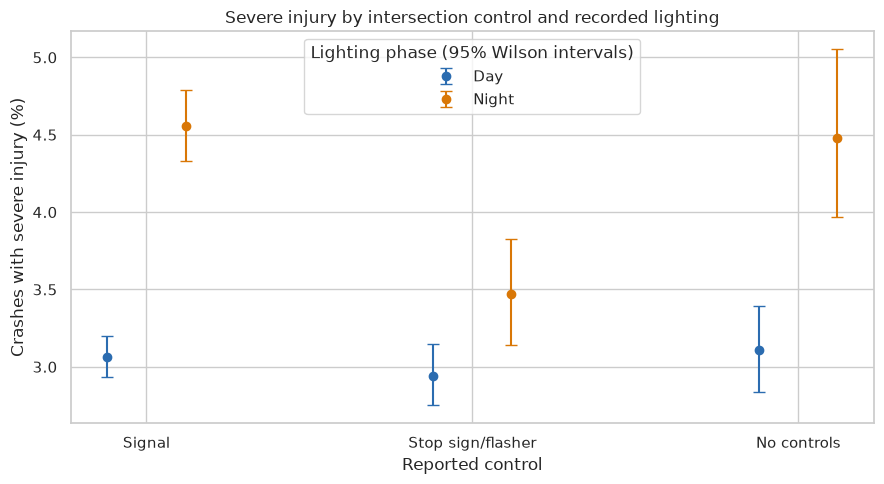

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
locations = np.arange(len(devices))
for phase, offset, color in [("Day", -.12, "#2B6CB0"), ("Night", .12, "#D97706")]:
    rows = phase_rates.loc[phase_rates["phase"].eq(phase)].set_index(DEVICE).loc[devices]
    interval = np.vstack([rows["pct"] - rows["low_pct"], rows["high_pct"] - rows["pct"]])
    ax.errorbar(locations + offset, rows["pct"], yerr=interval, fmt="o", capsize=4, color=color, label=phase)
ax.set_xticks(locations, [labels[dev] for dev in devices])
ax.set(title="Severe injury by intersection control and recorded lighting", xlabel="Reported control", ylabel="Crashes with severe injury (%)")
ax.legend(title="Lighting phase (95% Wilson intervals)")
fig.tight_layout()
plt.show()

### Compare the devices in shared collision and lighting strata

Within each combination of phase and first collision type, we require at least 100 records for **each** of the three controls. We show within-stratum shares and then standardize the devices to the same distribution of collision types and lighting phases. The reference weights are each included stratum's proportion of the pooled records from all three devices. We also show crude percentages in the same common-support cohort so the effect of reweighting can be seen separately from the effect of excluding sparse strata.

Q6 common-support strata: 34 -> 18
Q6 require 100 records per device in each phase/type stratum: 156,698 -> 153,173 rows (3,525 excluded)


traffic_control_device              Signal  Stop sign/flasher  No controls
phase first_crash_type                                                    
Day   ANGLE                           4.70               2.78         2.30
      FIXED OBJECT                    5.34               3.76         4.97
      HEAD ON                         6.53               5.77         5.60
      PARKED MOTOR VEHICLE            0.20               2.61         0.52
      PEDALCYCLIST                    9.59               8.29        11.69
      PEDESTRIAN                     17.37              15.15        21.47
      REAR END                        0.98               1.00         1.44
      SIDESWIPE OPPOSITE DIRECTION    3.70               1.09         1.29
      SIDESWIPE SAME DIRECTION        0.45               0.61         0.91
      TURNING                         2.22               1.89         2.32
Night ANGLE                           6.69               3.10         3.31
      FIXED OBJECT                    6.11               3.96         4.90
      PARKED MOTOR VEHICLE            3.75               1.86         0.94
      PEDALCYCLIST                   12.50              13.26        16.54
      PEDESTRIAN                     20.76              15.92        26.15
      REAR END                        1.51               1.38         1.77
      SIDESWIPE SAME DIRECTION        0.84               0.77         1.14
      TURNING                         3.11               2.24         3.25

,crashes,crude_pct_same_rows,standardized_pct,standardized_difference_vs_no_controls_pp
traffic_control_device,,,,
TRAFFIC SIGNAL,94911,3.55,3.83,0.38
STOP SIGN/FLASHER,38395,3.10,2.80,-0.65
NO CONTROLS,19867,3.44,3.45,0.00


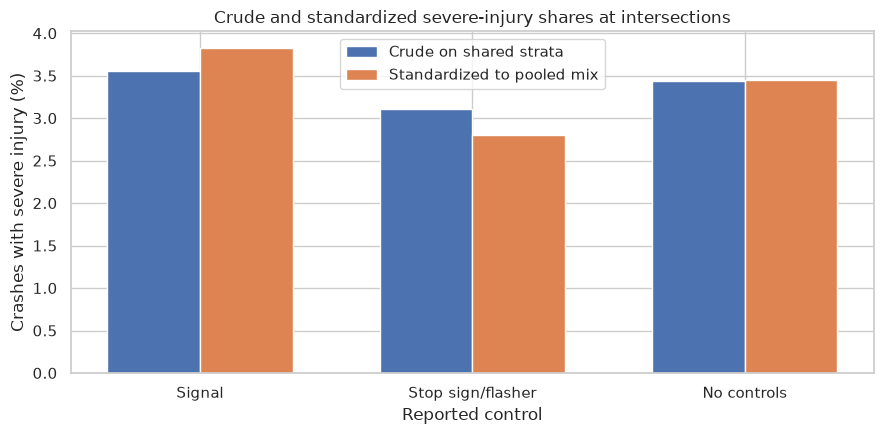

In [7]:
strata = ["phase", COLLISION]
counts = cohort.groupby(strata + [DEVICE], observed=True).size().unstack(DEVICE, fill_value=0)
counts = counts.reindex(columns=devices, fill_value=0)
supported = counts.index[counts.ge(100).all(axis=1)]
row_strata = pd.MultiIndex.from_frame(cohort[strata])
print(f"Q6 common-support strata: {len(counts)} -> {len(supported)}")
common = restrict(cohort, row_strata.isin(supported), "Q6 require 100 records per device in each phase/type stratum")
assert len(common) > 0

within_device = event_summary(common, strata + [DEVICE], SEVERE)
stratum_rates = within_device.pivot(index=strata, columns=DEVICE, values="pct").loc[:, devices]
display(stratum_rates.rename(columns=labels).round(2))

weights = counts.loc[stratum_rates.index].sum(axis=1)
weights = weights / weights.sum()
standardized = stratum_rates.mul(weights, axis=0).sum().rename("standardized_pct")
comparison = event_summary(common, [DEVICE], SEVERE).set_index(DEVICE).loc[devices, ["crashes", "pct"]]
comparison = comparison.rename(columns={"pct": "crude_pct_same_rows"})
comparison["standardized_pct"] = standardized
comparison["standardized_difference_vs_no_controls_pp"] = standardized - standardized.loc["NO CONTROLS"]
display(comparison.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
device_index = np.arange(len(devices))
ax.bar(device_index - .17, comparison["crude_pct_same_rows"], .34, label="Crude on shared strata")
ax.bar(device_index + .17, comparison["standardized_pct"], .34, label="Standardized to pooled mix")
ax.set_xticks(device_index, [labels[dev] for dev in devices])
ax.set(title="Crude and standardized severe-injury shares at intersections", xlabel="Reported control", ylabel="Crashes with severe injury (%)")
ax.legend()
fig.tight_layout()
plt.show()

### Hour by weekday pivot

This view uses the main day/night cohort across all three controls. The count heatmap shows how many crash records are available. The severity heatmap masks cells with fewer than 100 records; those crash records remain in the count heatmap.

Severity heatmap cells withheld for low support: 1
Highest count cell: (15, 'Fri') 2090


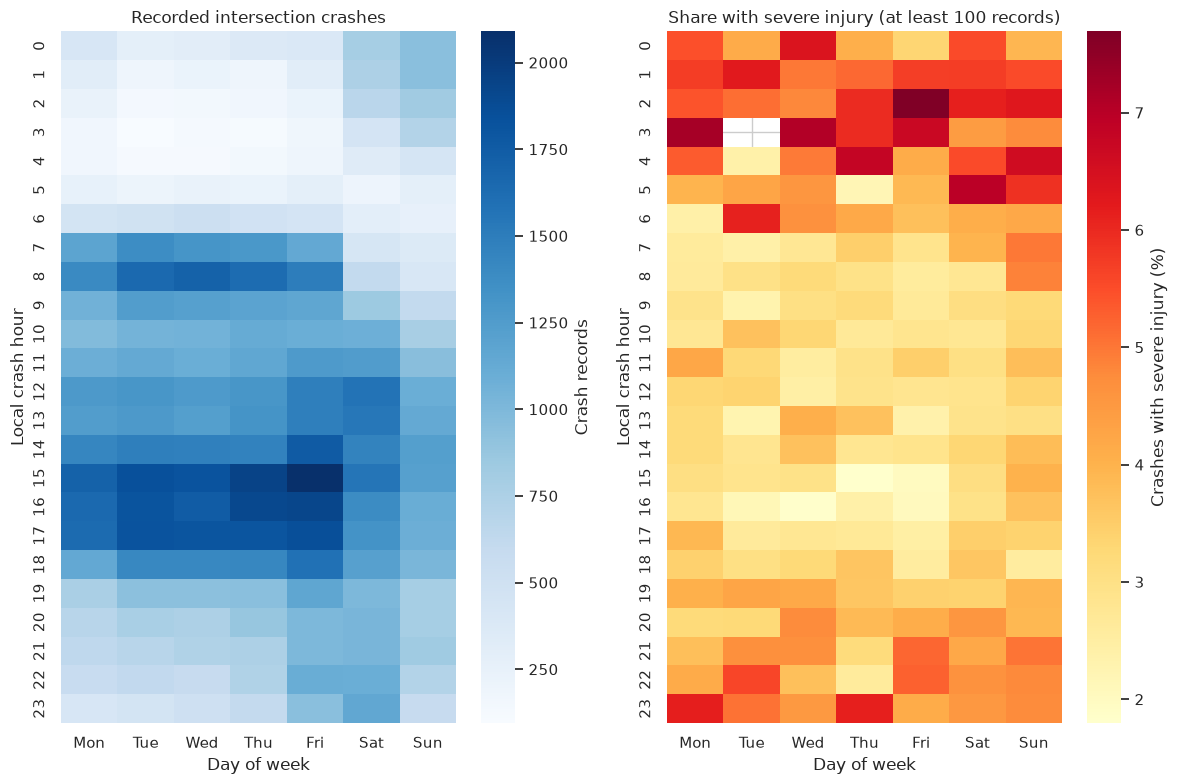

In [8]:
weekday = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
cohort["weekday"] = cohort["crash_day_of_week"].map(weekday)
pivot_counts = pd.crosstab(cohort["crash_hour"], cohort["weekday"]).reindex(
    index=range(24), columns=day_order, fill_value=0
)
pivot_rate = cohort.pivot_table(
    index="crash_hour", columns="weekday", values=SEVERE, aggfunc="mean", observed=True
).reindex(index=range(24), columns=day_order).mul(100)
assert pivot_counts.to_numpy().sum() == len(cohort)
print(f"Severity heatmap cells withheld for low support: {(pivot_counts < 100).to_numpy().sum()}")
print("Highest count cell:", pivot_counts.stack().idxmax(), int(pivot_counts.to_numpy().max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 8))
sns.heatmap(pivot_counts, cmap="Blues", cbar_kws={"label": "Crash records"}, ax=axes[0])
sns.heatmap(pivot_rate, mask=pivot_counts.lt(100), cmap="YlOrRd", cbar_kws={"label": "Crashes with severe injury (%)"}, ax=axes[1])
for ax, title in zip(axes, ["Recorded intersection crashes", "Share with severe injury (at least 100 records)"]):
    ax.set(title=title, xlabel="Day of week", ylabel="Local crash hour")
fig.tight_layout()
plt.show()

### Q6 results and interpretation

Among **156,698** intersection-related records in the selected control and lighting groups, the crude severe-injury percentages were **3.56%** for signals, **3.09%** for stop signs/flashers and **3.48%** for no controls. The nighttime percentages were **4.55%, 3.47%, and 4.48%**, respectively, compared with **3.06%, 2.94%, and 3.11%** in daylight.

Within the **18** supported collision/lighting strata (**153,173** records), standardizing to a common mix gave **3.83%** for signals, **2.80%** for stop signs/flashers and **3.45%** for no controls. Device order varied within strata. For nighttime angle crashes, signals had a severe share of **6.69%** and no controls had **3.31%**. For nighttime pedestrian crashes, signals had **20.76%** and no controls had **26.15%**. The hour-by-weekday pivot recorded the most crashes in the **Friday 15:00** cell (**2,090**).

These differences can guide follow-up by time and collision type. Speeds, intersection design, road-user mix, reporting and traffic volumes may differ across control groups. A device's severe share among recorded crashes cannot identify its effect on the chance of a severe crash per trip.

AI contributions to code and draft interpretation are recorded in `LLM_USAGE.md`.